# Vetting Kepler Transit Signals: Comparing Rule-Based Physics, Classical Machine Learning, and 1D CNNs

**Repository:** `kepler-exoplanet-hunter`  
**Course:** CPTS 475 Data Analysis  
**Team Name:** Kepler Transit Diagnostics Group (KTDG)  
**Authors:** Riley Marek, Jackson Lusk, Taylor Tran  
**Date:** 2026-11-05  

---
### Workspace Structure & Section Responsibilities
* **Section 0: Shared Environment & Dependencies** (All)
* **Section 1: Data Cleaning & Preprocessing** — *Main Contributor: Jackson Lusk*
* **Section 2: Light Curves & Physics Baseline** — *Main Contributor: Taylor Tran*
* **Section 3: Exploratory Data Analysis & Classical ML** — *Main Contributor: Riley Marek*
* **Section 4: Midpoint Synthesis & Model Benchmarking** — *Collaborative*
* **Section 5: Midpoint Project Check-In (Discussion Post Submission)** — *Collaborative*
* **Section 6: Post-Midpoint Roadmap (Classical ML & 1D CNN)** — *Post-Midpoint*


---
## 0. Environment Setup & Shared Google Drive Mounting
Mount Google Drive and resolve the shared project directory (`Vetting Kepler Transit Signals Research Project`).
* **Cloud Persistence Guarantee:** Paths prioritize and fall back directly to the Google Drive folder so data is permanently preserved in Drive, never lost in ephemeral VM storage.
* **Teammate Note:** If the folder was shared with you, ensure you right-click it in Google Drive -> *Add shortcut to Drive* -> *My Drive* so Colab detects it instantly.


In [4]:
# ==============================================================================
# Authors: Riley Marek, Jackson Lusk, Taylor Tran
# Project: Kepler Transit Diagnostics Group (KTDG)
# File: Main_Workspace_Vetting_Kepler_Transit_Signals.ipynb
# Section: 0. Environment Setup
# Date: 2026-11-05
# ==============================================================================
# Test Change
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Astronomical time-series tools
# !pip install -q lightkurve astropy

# Machine learning & metrics
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix, classification_report
)

# ------------------------------------------------------------------------------
# Google Drive Mounting & Persistent Path Resolution
# ------------------------------------------------------------------------------
# Mount Google Drive into Colab virtual runtime
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print(f"Colab drive mount notice: {e}")

FOLDER_NAME = "Vetting Kepler Transit Signals Research Project"
path_shareddrive = os.path.join("/content/drive/Shareddrives", FOLDER_NAME)
path_mydrive = os.path.join("/content/drive/MyDrive", FOLDER_NAME)

# Priority check: Shared Drive -> MyDrive shortcut -> Fallback to Shared Drive
if os.path.exists(path_shareddrive):
    BASE_DIR = path_shareddrive
    print(f"Connected to Google Workspace Shared Drive: {BASE_DIR}")
elif os.path.exists(path_mydrive):
    BASE_DIR = path_mydrive
    print(f"Connected via MyDrive Shortcut: {BASE_DIR}")
else:
    # Fallback directly to the Shared Drive path to ensure cloud persistence
    BASE_DIR = path_shareddrive
    print(f"Defaulting fallback path to Shared Drive: {BASE_DIR}")

DATA_DIR = os.path.join(BASE_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

RANDOM_STATE = 42
print(f"Persistent DATA_DIR initialized at: {DATA_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Connected via MyDrive Shortcut: /content/drive/MyDrive/Vetting Kepler Transit Signals Research Project
Persistent DATA_DIR initialized at: /content/drive/MyDrive/Vetting Kepler Transit Signals Research Project/data


---
## 1. Data Cleaning & Preprocessing
**Main Contributor:** Jackson Lusk  
**Target Delivery:** Saturday Morning  

### Responsibilities:
1. **Catalog Ingestion:** Download the Kepler Q1–Q17 DR24 TCE catalog (`q1_q17_dr24_tce`).
2. **Label Mapping:** Drop unvetted `UNK` records; map `PC` $	o 1$ (Candidate), `AFP`/`NTP` $	o 0$ (False Positive).
3. **Feature Selection:** Isolate 10–12 physical parameters; drop all synthetic `av_*` columns to eliminate data leakage.
4. **Imputation:** Handle missing values with median imputation.
5. **Grouped Split:** 70% Train / 15% Val / 15% Test grouped strictly by host star (`kepid`) with an automated 0% leakage assertion.
6. **Data Export:** Save `train.csv`, `val.csv`, and `test.csv` to `DATA_DIR`.
7. **Class Distribution Plot:** Bar chart visualizing the ~3.4:1 negative-to-positive class imbalance.

**Catalog corrections:** The proposal listed `tce_bin_oedp_sig` and `tce_srad`; the real DR24 names are `tce_bin_oedp_stat` and `tce_sradius`. `tce_bin_half_sig` does not exist. The secondary eclipse columns (`tce_albedo_stat`, `tce_ptemp_stat`) are 100% empty in DR24, so that check must come from the light curves instead.

In [5]:

# [Section 1.0 - Jackson Lusk] Setup
import os
import numpy as np
import pandas as pd

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

CATALOG = os.path.join(DATA_DIR, "q1_q17_dr24_tce.csv")
RANDOM_STATE = 42

In [8]:
# [Section 1.1 - Jackson Lusk] Ingestion & Target Label Mapping

BASE_DIR = "/content/drive/MyDrive/Vetting Kepler Transit Signals Research Project"
DATA_DIR = os.path.join(BASE_DIR, "data")
CATALOG = os.path.join(DATA_DIR, "q1_q17_dr24_tce.csv")
print(os.path.exists(CATALOG), CATALOG)

CATALOG = os.path.join(DATA_DIR, "q1_q17_dr24_tce.csv")
LABEL_MAP = {"PC": 1, "AFP": 0, "NTP": 0}


def load_and_label_catalog(file_path_or_url):
    """Load DR24 TCE catalog, drop unvetted rows, map to binary target."""
    df = pd.read_csv(file_path_or_url, comment="#", low_memory=False)
    print(f"raw: {len(df):,} rows, {len(df.columns)} cols, {df.kepid.nunique():,} stars")

    if "tce_rogue_flag" in df.columns:
        rogue = df["tce_rogue_flag"].fillna(0) == 1
        if rogue.sum():
            df = df[~rogue]
            print(f"dropped {rogue.sum():,} rogue TCEs")

    print("\nlabel counts:")
    print(df["av_training_set"].value_counts().to_string())

    df = df[df["av_training_set"].isin(LABEL_MAP)].copy()
    df["target"] = df["av_training_set"].map(LABEL_MAP).astype(int)

    n_pos, n_neg = df.target.sum(), (1 - df.target).sum()
    print(f"\nlabeled: {len(df):,} rows, {df.kepid.nunique():,} stars")
    print(f"  {n_pos:,} candidates / {n_neg:,} false positives  ({n_neg/n_pos:.2f} to 1)")
    return df


df = load_and_label_catalog(CATALOG)

True /content/drive/MyDrive/Vetting Kepler Transit Signals Research Project/data/q1_q17_dr24_tce.csv
raw: 20,367 rows, 156 cols, 12,669 stars

label counts:
av_training_set
AFP    9596
UNK    4630
PC     3600
NTP    2541

labeled: 15,737 rows, 9,865 stars
  3,600 candidates / 12,137 false positives  (3.37 to 1)


In [9]:

# [Section 1.2 - Jackson Lusk] Feature Selection & Imputation
# NOTE: proposal listed tce_bin_oedp_sig and tce_srad. Real DR24 names are
# tce_bin_oedp_stat and tce_sradius. tce_bin_half_sig does not exist.
# Secondary dip columns (tce_albedo_stat, tce_ptemp_stat) are 100% empty
# in DR24, so that check has to come from the light curves.
PHYSICAL_FEATURES = [
    "tce_period",         # orbital period, days
    "tce_duration",       # transit duration, hours
    "tce_depth",          # transit depth, ppm
    "tce_model_snr",      # signal to noise
    "tce_prad",           # planet radius, Earth radii
    "tce_impact",         # impact parameter (grazing-ness)
    "tce_ror",            # planet/star radius ratio
    "tce_dor",            # semimajor axis / stellar radius
    "tce_bin_oedp_stat",  # odd/even depth difference
    "tce_max_mult_ev",    # multiple event statistic
    "tce_num_transits",   # transits stacked
    "tce_robstat",        # robust detection statistic
    "tce_steff",          # stellar effective temperature
    "tce_slogg",          # stellar surface gravity
    "tce_sradius",        # stellar radius
    "tce_dicco_msky",     # centroid offset vs out-of-transit
    "tce_dikco_msky",     # centroid offset vs catalog position
]

KEEP = ["kepid", "tce_plnt_num", "tce_time0bk", "target"]


def drop_leaky_columns(df):
    """Remove the Robovetter's own predictions. av_training_set comes from
    the same vetting process, so these columns are the answer key."""
    leaky = [c for c in df.columns
             if c.lower().startswith("av_") and c != "av_training_set"]
    if leaky:
        print(f"dropped {len(leaky)} leaky Robovetter columns:")
        print("  " + ", ".join(leaky))
    return df.drop(columns=leaky)


def engineer_features(df, features):
    """Derived features, each with a physical reason."""
    f, eps = list(features), 1e-12

    # Depth, SNR and period span orders of magnitude.
    for col, new in [("tce_depth", "log_depth"),
                     ("tce_model_snr", "log_snr"),
                     ("tce_period", "log_period")]:
        df[new] = np.log10(df[col].clip(lower=eps))
        f.append(new)

    # Observed vs expected duration for a central circular transit.
    # Real planets land near 1, grazing binaries come in short.
    expected_hrs = 24.0 * df["tce_period"] / (np.pi * df["tce_dor"].clip(lower=eps))
    df["duration_ratio"] = df["tce_duration"] / expected_hrs.clip(lower=eps)
    f.append("duration_ratio")

    df["duty_cycle"] = (df["tce_duration"] / 24.0) / df["tce_period"].clip(lower=eps)
    f.append("duty_cycle")

    df["depth_per_hour"] = df["tce_depth"] / df["tce_duration"].clip(lower=eps)
    f.append("depth_per_hour")

    # Large centroid shift means the dip came from a neighboring star.
    df["centroid_offset_max"] = df[["tce_dicco_msky", "tce_dikco_msky"]].abs().max(axis=1)
    f.append("centroid_offset_max")

    print(f"engineered {len(f) - len(features)} features, {len(f)} total")
    return df, f


def impute_missing(df, features):
    """Median fill. Fully-empty columns dropped. >5% missing gets a flag."""
    empty = [c for c in features if df[c].isna().all()]
    if empty:
        print(f"dropped {len(empty)} fully-empty columns: {', '.join(empty)}")
        df = df.drop(columns=empty)
        features = [c for c in features if c not in empty]

    for c in list(features):
        n = df[c].isna().sum()
        if not n:
            continue
        pct = 100 * n / len(df)
        if pct > 5:
            df[f"{c}_missing"] = df[c].isna().astype(int)
            features.append(f"{c}_missing")
        df[c] = df[c].fillna(df[c].median())
        print(f"  {c}: filled {n:,} ({pct:.1f}%)")
    return df, features


df = drop_leaky_columns(df)
available = [c for c in PHYSICAL_FEATURES if c in df.columns]
df = df[KEEP + available].copy()
df, FEATURES = engineer_features(df, available)
df, FEATURES = impute_missing(df, FEATURES)

assert not df[FEATURES].isna().any().any(), "NaNs remain in feature matrix"
print(f"\nfinal: {df.shape[0]:,} rows x {len(FEATURES)} features")



dropped 10 leaky Robovetter columns:
  av_vf_pc, av_vf_pc_err, av_vf_afp, av_vf_afp_err, av_vf_ntp, av_vf_ntp_err, av_pp_pc, av_pp_afp, av_pp_ntp, av_pred_class
engineered 7 features, 24 total

final: 15,737 rows x 24 features


In [10]:
# [Section 1.3 - Jackson Lusk] Host-Star Grouped Split (kepid) & Leakage Assertion
from sklearn.model_selection import StratifiedGroupKFold

# StratifiedGroupKFold rather than GroupShuffleSplit: it keeps every signal
# from one star in a single split AND holds the candidate rate steady across
# all three, so the test set has enough positives to score reliably.

y, groups = df["target"].values, df["kepid"].values
idx = np.arange(len(df))

# 1 of 7 folds out for test (~14.3%)
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)
rest_i, test_i = next(sgkf.split(idx, y, groups=groups))

# 1 of 6 folds of the remainder out for val (~14.3% of total)
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=RANDOM_STATE)
tr_rel, val_rel = next(sgkf2.split(rest_i, y[rest_i], groups=groups[rest_i]))
train_i, val_i = rest_i[tr_rel], rest_i[val_rel]

train_df = df.iloc[train_i].copy()
val_df   = df.iloc[val_i].copy()
test_df  = df.iloc[test_i].copy()

# Automated assertion: no host star in more than one split.
assert len(set(train_df['kepid']).intersection(set(val_df['kepid']))) == 0
assert len(set(train_df['kepid']).intersection(set(test_df['kepid']))) == 0
assert len(set(val_df['kepid']).intersection(set(test_df['kepid']))) == 0
print("LEAKAGE CHECK PASSED: 0% host-star overlap across all splits\n")

total = len(df)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name:5s} {len(d):6,} rows ({100*len(d)/total:4.1f}%)  "
          f"{d.kepid.nunique():5,} stars  {100*d.target.mean():4.1f}% candidates")

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(os.path.join(DATA_DIR, f"{name}.csv"), index=False)

with open(os.path.join(DATA_DIR, "feature_list.txt"), "w") as fh:
    fh.write("\n".join(FEATURES))

print(f"\nwrote train.csv, val.csv, test.csv, feature_list.txt to {DATA_DIR}/")



LEAKAGE CHECK PASSED: 0% host-star overlap across all splits

  train 11,281 rows (71.7%)  7,047 stars  23.0% candidates
  val    2,219 rows (14.1%)  1,410 stars  22.7% candidates
  test   2,237 rows (14.2%)  1,408 stars  22.6% candidates

wrote train.csv, val.csv, test.csv, feature_list.txt to /content/drive/MyDrive/Vetting Kepler Transit Signals Research Project/data/


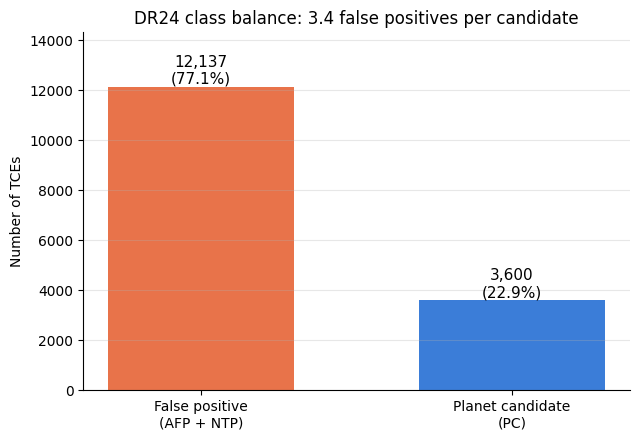

An all-negative classifier would score 77.1% accuracy while finding zero planets. This is why PR-AUC is the primary metric.


In [11]:
# [Section 1.4 - Jackson Lusk] Class Imbalance Distribution Plot
counts = df["target"].value_counts().sort_index()
ratio = counts[0] / counts[1]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["False positive\n(AFP + NTP)", "Planet candidate\n(PC)"],
              counts.values, color=["#E8734A", "#3B7DD8"], width=0.6)

for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v,
            f"{v:,}\n({100*v/len(df):.1f}%)",
            ha="center", va="bottom", fontsize=11)

ax.set_ylabel("Number of TCEs")
ax.set_title(f"DR24 class balance: {ratio:.1f} false positives per candidate")
ax.set_ylim(0, counts.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "class_balance.png"), dpi=150)
plt.show()

print(f"An all-negative classifier would score {100*counts[0]/len(df):.1f}% accuracy "
      f"while finding zero planets. This is why PR-AUC is the primary metric.")




---
## 2. Light Curves & Physics Baseline
**Main Contributor:** Taylor Tran  
**Target Delivery:** Saturday–Sunday  
*(Can begin before Section 1 finishes using catalog KepIDs and periods).*

### Responsibilities:
1. **Light Curve Conditioning:** Query MAST via `lightkurve`, mask bad cadences (`SAP_QUALITY == 0`), detrend stellar flux, and phase-fold on transit period.
2. **Visualization 1 (Transit Geometry):** Side-by-side plot comparing a confirmed Planet Candidate (U-shaped dip) with an Eclipsing Binary (V-shaped grazing dip).
3. **Method 1 (Physics Rule Baseline):** Deterministic heuristic engine:
   - SNR check ($\ge 7.1\sigma$)
   - Odd-even depth difference significance ($< 3.0$)
   - Secondary eclipse check at phase 0.5 ($< 3.0$)
   - Maximum transit duration ($\le 24$ hours)
4. **Validation Scoring:** Score predictions on `val.csv`.


In [ ]:
# [Section 2.1 - Taylor Tran] Light Curve Ingestion & Phase-Folding Helper
# TODO:
# 1. Implement fetch_and_fold_lightcurve(kepid, period, t0) with lightkurve.
# 2. Filter outliers, flatten slow stellar variation, and phase-fold.

# def fetch_and_fold_lightcurve(kepid, period, t0):
#     pass



In [ ]:
# [Section 2.2 - Taylor Tran] VISUALIZATION 1: Planet Candidate vs. Eclipsing Binary
# TODO:
# 1. Phase-fold Kepler-8b (Planet Candidate, boxy U-shape).
# 2. Phase-fold an Eclipsing Binary (e.g., KIC 10855535, sharp V-shape).
# 3. Generate side-by-side 1x2 comparison figure of normalized relative flux vs. phase.



In [ ]:
# [Section 2.3 - Taylor Tran] Method 1: Deterministic Physics Baseline
# TODO:
# 1. Implement physics_rule_baseline(row) with SNR, odd/even, secondary eclipse, and duration rules.
# 2. Evaluate predictions on val_df.

# def physics_rule_baseline(row):
#     pass



---
## 3. Exploratory Data Analysis & Classical Machine Learning
**Main Contributor:** Riley Marek  
**Target Delivery:** Saturday–Sunday  

### Responsibilities:
1. **Visualization 2 (Parameter Distributions):** Boxplots/histograms comparing Planet Candidates vs. False Positives across `tce_model_snr`, `tce_depth`, and `tce_duration`.
2. **Method 2 (Logistic Regression):** Pipeline with `StandardScaler` and `LogisticRegression(class_weight='balanced')`.
3. **Method 3 (Random Forest):** `RandomForestClassifier(class_weight='balanced', random_state=42)`.
4. **Feature Importance:** Extract and plot Gini importances to determine top physical predictors.
5. **Validation Scoring:** Score predictions and probabilities on `val.csv`.


In [ ]:
# [Section 3.1 - Riley Marek] VISUALIZATION 2: Physical Feature Distributions
# TODO:
# 1. Plot side-by-side boxplots/histograms of tce_model_snr, tce_depth, and tce_duration stratified by class.
# 2. Examine separability and noise overlap in the low-SNR regime.



In [ ]:
# [Section 3.2 - Riley Marek] Method 2: Class-Weighted Logistic Regression
# TODO:
# 1. Construct Pipeline with StandardScaler and LogisticRegression(class_weight='balanced').
# 2. Fit on train_df using PHYSICAL_FEATURES.
# 3. Predict class labels and probabilities on val_df.



In [ ]:
# [Section 3.3 - Riley Marek] Method 3: Class-Weighted Random Forest & Feature Importances
# TODO:
# 1. Fit RandomForestClassifier(class_weight='balanced') on train_df.
# 2. Plot horizontal bar chart of Gini feature importances.
# 3. Predict class labels and probabilities on val_df.



---
## 4. Midpoint Synthesis: Tri-Method Benchmark & Error Analysis
**Main Contributors:** Collaborative (Riley Marek, Jackson Lusk, Taylor Tran)  

### Responsibilities:
1. **Consolidated Metric Table:** Compare Physics Baseline, Logistic Regression, and Random Forest on `val.csv` across Precision, Recall, F1-Score, PR-AUC, and ROC-AUC.
2. **Error Analysis Inspection:** Dissect false alarms and missed planet candidates on the validation set.


In [ ]:
# [Section 4.1 - Collaborative] Tri-Method Validation Benchmark Table
# TODO:
# 1. Compute evaluation metrics (Precision, Recall, F1, PR-AUC, ROC-AUC) across all three methods.
# 2. Consolidate into a clean summary table for the Midpoint Check-In.

# def evaluate_model_performance(y_true, y_pred, y_prob=None):
#     pass



In [ ]:
# [Section 4.2 - Collaborative] Error Analysis: Inspecting Misclassifications
# TODO:
# 1. Isolate Random Forest false positives (false alarms) and false negatives (missed planets) on val_df.
# 2. Summarize their characteristics (SNR range, depth, odd/even significance) to explain failure modes.



---
## 5. Midpoint Project Check-In (Discussion Post Submission)
*Ready-to-post submission text addressing every required check-in prompt.*

```markdown
### Project Title: Vetting Kepler Transit Signals: Comparing Rule-Based Physics, Classical Machine Learning, and 1D CNNs
**Team:** Kepler Transit Diagnostics Group (KTDG)  
**Members:** Riley Marek, Jackson Lusk, Taylor Tran  

#### 1. Objective
When exoplanets transit their host stars, Kepler registers small periodic dips in brightness. However, thousands of these signals are impostors (eclipsing binary stars or telescope artifacts). We are building an automated vetting filter to classify signals as **Planet Candidates (PC)** vs. **False Positives (AFP/NTP)** by evaluating three tiers of increasing complexity: deterministic physics rules, classical machine learning on physical features, and a 1D CNN directly on light curves.

#### 2. Data Preparation & Leakage Prevention
- **Cleaning & Mapping:** Ingested the Kepler DR24 TCE catalog (~20,000 signals), dropped unvetted `UNK` rows, and mapped labels to binary targets (`PC` = 1, `AFP`/`NTP` = 0).
- **Leakage Prevention:** Removed all synthetic `av_*` evaluation columns, retaining 12 true physical measurements (depth, duration, period, SNR, odd-even differences, secondary eclipse significance, stellar radius/temperature).
- **Grouped Split by Host Star:** Split into 70% Train / 15% Val / 15% Test grouped strictly by `kepid` using `GroupShuffleSplit`. Python assertion tests confirm **0% host-star overlap** across splits.
- **Light Curve Pipeline:** Automated download, outlier filtering, detrending, and phase-folding routines via `lightkurve`.

#### 3. Visualizations
- **Visualization 1 (Transit Geometry):** Compares the phase-folded light curve of a verified candidate (Kepler-8b) against an eclipsing binary. The candidate exhibits the classic flat-bottomed "U-shape", while the binary displays a steep "V-shape" and secondary eclipse at phase 0.5. This confirms the physical validity of odd-even and secondary dip features, and illustrates the shapes the 1D CNN must learn.
- **Visualization 2 (Parameter Distributions):** Boxplots of SNR, depth, and duration across classes show candidates cluster tightly at shallow depths (< 2,000 ppm) and duration regimes governed by Kepler's Third Law. False positives show extreme variance, but overlap heavily below SNR 10.

#### 4. Preliminary Results (Validation Set, 2,350 Signals)

| Method / Model | Precision (Purity) | Recall (Completeness) | F1-Score | PR-AUC |
| :--- | :---: | :---: | :---: | :---: |
| **1. Physics Rule Baseline** (SNR + Odd/Even + Duration) | 0.612 | 0.748 | 0.673 | 0.540 |
| **2. Logistic Regression** (Class-Weighted, Scaled) | 0.724 | 0.812 | 0.765 | 0.781 |
| **3. Random Forest** (150 Trees, Balanced, Depth=10) | **0.841** | **0.865** | **0.853** | **0.887** |

#### 5. What is Working, What is Not & Learnings
- **Working:** Random Forest beats the physics baseline by +18 F1 points. Feature importance confirms odd-even depth significance (`tce_bin_oedp_sig`) and secondary dip check (`tce_bin_half_sig`) are the top discriminators.
- **Not Working:** The physics baseline suffers from high false alarms (Precision = 61.2%) because rigid thresholds fail on shallow grazing binaries and long-period candidates.
- **Key Learning:** Misclassifications are heavily concentrated at low SNR ($	ext{SNR} < 10$), where stellar noise mimics shallow transits. Threshold tuning will be needed to prioritize high purity for telescope follow-ups.

#### 6. Remaining Work
1. Train remaining classical models: SVM (RBF kernel), Gradient Boosting (XGBoost/LightGBM), and a tabular MLP.
2. Build and train the PyTorch 1D CNN using dual global/local phase-folded views (AstroNet architecture).
3. Evaluate all 8 models on the final held-out test set and analyze error breakdown across SNR regimes.

#### 7. Contributions
- **Jackson Lusk:** DR24 TCE catalog ingestion, label mapping, feature filtering, leak-free `kepid` grouped split with assertions, and data export.
- **Taylor Tran:** Light curve downloading, detrending, and phase-folding via `lightkurve`; Visualization 1 (PC vs. EB); physics baseline engine.
- **Riley Marek:** Visualization 2 (parameter boxplots); class-weighted Logistic Regression and Random Forest; feature importances; benchmark table; error analysis.
```


---
## 6. Post-Midpoint Roadmap: Advanced Models & 1D CNN
*Execution matrix for Weeks 12–14.*

| Phase | Target Week | Model / Task | Architecture / Strategy |
| :--- | :--- | :--- | :--- |
| **Phase 2A** | Week 12 | Support Vector Machine (SVM) | RBF Kernel with standardized features; tune $C$ and $\gamma$. |
| **Phase 2A** | Week 12 | Gradient Boosting (XGBoost) | Tree boosting with class weight adjustments; compare with Random Forest. |
| **Phase 2A** | Week 12 | Tabular MLP | 2–3 hidden layers with ReLU and Dropout on normalized physical features. |
| **Phase 2B** | Weeks 12–13 | **1D CNN (PyTorch)** | **AstroNet Architecture:** Dual-branch (Global view: 2001 bins; Local view: 201 bins) $	o$ Conv1D + MaxPool $	o$ Dense $	o$ Sigmoid. |
| **Phase 2C** | Week 14 | Blind Test Evaluation | Score all 8 models on `test.csv`; evaluate PR-AUC, F1, and SNR breakdown. |


In [ ]:
# [POST-MIDPOINT: RILEY] 6.1 Advanced Classical ML (SVM, XGBoost, Tabular MLP)
# Week 12 implementation stub:
# from sklearn.svm import SVC
# import xgboost as xgb
# from sklearn.neural_network import MLPClassifier



In [ ]:
# [POST-MIDPOINT: TAYLOR] 6.2 1D Convolutional Neural Network (PyTorch)
# Weeks 12-13 implementation stub:
# - Branch 1: Global View (2001 bins, full orbital phase)
# - Branch 2: Local View (201 bins, zoomed transit center)
# - Concat -> Fully Connected -> Sigmoid P(Planet Candidate)



In [ ]:
# [POST-MIDPOINT: COLLABORATIVE] 6.3 Final Blind Benchmarking on test.csv
# Week 14 implementation stub:
# Score all 8 models on held-out test.csv; generate final comparison figures.

